# Delano diagrams: first order layout of a lithography lens

Delano's $y$-$\bar y$ diagram plots the height $\bar y$ of the paraxial
chief ray against the height $y$ of the paraxial marginal ray at every lens
(or surface). A system becomes a polygon, and all of its first order
properties can be read off it: powers, spacings, stop and pupils,
telecentricity, conjugates, cardinal points. The other way round, a lens can
be *drawn* as a polygon and then built from it. This is how complex systems
such as lithographic projection lenses are laid out before any surface is
bent (Delano 1963; Shack 1973; Matsuyama, Ohmura and Williamson, "The
lithographic lens: its history and evolution", Proc. SPIE 6154, 2006).

This notebook

1. reads the diagram of Caldwell's KrF lens (`DelanoDiagram.from_system()`),
2. shows the rules of the diagram with a three lens relay,
3. lays out a new KrF projection lens in the diagram: **13 elements, 1 m from
   object to wafer, magnification −0.25, NA 0.7**, telecentric on both sides,
   with a flat field (Petzval sum zero) — first as a hand drawn sketch, then
   polished with `delano.refine()`,
4. turns the thin lens layout into fused silica singlets with the same first
   order properties (`delano.thicken()`),
5. corrects the aberrations with real rays (`lens_optimization.LensOptimizer`)
   and checks the result.

Conventions (module `pyoptics.delano`): points $P = (\bar y, y)$, reduced
slopes $\omega = n u$, Lagrange invariant $H = n(\bar u y - u \bar y)$, as
`raytrace.Paraxial.lagrange`. Lengths in mm.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import lens_optimization as lo
from pyoptics.delano import DelanoDiagram, refine, thicken

plt.rcParams.update({"figure.dpi": 80, "font.size": 11})
t_start = time.time()

## 1. The diagram of a real lens

`DelanoDiagram.from_system()` takes the paraxial marginal and chief rays of a
`raytrace.System`: one point per surface vertex, plus the object and the
image point. Caldwell's all fused silica KrF lens (21 elements, NA 0.56, 4x,
1 m) as an example:

44 points: object, 42 surfaces, image; H = -6.2702 mm
powers from the corners vs. (n' - n)/R: max. difference 1.3e-16 1/mm
spaces from the triangle areas vs. the thicknesses: max. difference 7.5e-14 mm
magnification -0.25000 (paraxial -0.25000), NA 0.5359 (paraxial 0.5359), length 1000.01 mm
stop (y axis crossing) 701.8 mm behind the object, surface 30 at 701.8 mm; entrance pupil 10.0 m, exit pupil -2.6 m from the object


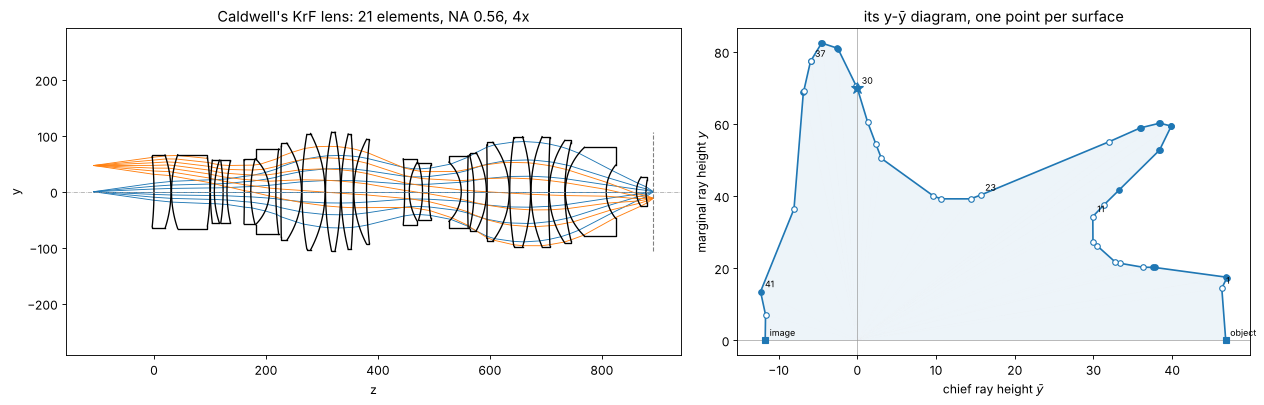

In [2]:
caldwell = rt.caldwell_krf_lens()
dc = DelanoDiagram.from_system(caldwell)
p = caldwell.paraxial()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.2, 1]})
caldwell.draw(axes[0], fields=[0.0, caldwell.max_field])
axes[0].set_title("Caldwell's KrF lens: 21 elements, NA 0.56, 4x")
dc.plot(axes[1], annotate=False, areas=True)
for k in [0, 1, 11, 23, 30, 37, 41, 43]:
    axes[1].annotate(dc.labels[k], (dc.ybar[k], dc.y[k]), xytext=(4, 4), textcoords="offset points",
                     fontsize=8)
axes[1].set_title("its y-ȳ diagram, one point per surface")
fig.tight_layout()

n_s = caldwell.n*caldwell.sigma
powers = np.array([s.paraxial_power(n_s[i], n_s[i + 1]) for i, s in enumerate(caldwell.surfaces)])
print(f"{len(dc)} points: object, 42 surfaces, image; H = {dc.H:.4f} mm")
print(f"powers from the corners vs. (n' - n)/R: max. difference {np.max(abs(dc.power - powers)):.1e} 1/mm")
print(f"spaces from the triangle areas vs. the thicknesses: max. difference "
      f"{np.max(abs(dc.thickness[1:-1] - [s.thickness for s in caldwell.surfaces[:-1]])):.1e} mm")
print(f"magnification {dc.magnification:.5f} (paraxial {p.magnification:.5f}), "
      f"NA {dc.NA[1]:.4f} (paraxial {p.na:.4f}), length {dc.length:.2f} mm")
pu = dc.pupils()
print(f"stop (y axis crossing) {pu.stop[0]:.1f} mm behind the object, surface 30 at "
      f"{caldwell.object_distance + caldwell.vertex_z[29]:.1f} mm; entrance pupil "
      f"{pu.entrance/1e3:.1f} m, exit pupil {pu.exit/1e3:.1f} m from the object")

How to read it:

- The polygon starts at the **object** on the $\bar y$ axis ($y = 0$, $\bar y$
  = object height 46.8 mm) and ends at the **image** ($\bar y = -11.7$ mm). It
  crosses the $y$ axis ($\bar y = 0$) once, at the **aperture stop**
  (star), here at surface 30.
- The first and the last edges are almost vertical: the chief ray is almost
  parallel to the axis in object and image space, the lens is (nearly)
  **telecentric** on both sides. The extended edges meet $\bar y = 0$ at the
  pupils, 9 m in front of and 2.6 m behind the lens.
- Every edge is a space: the shaded triangle that it spans with the origin
  has the area $H\tau/2$, with the reduced thickness $\tau = t/n$. Long air
  spaces far from the origin are large triangles; a glass element is two
  corners close together.
- Every corner is a surface: its power is the change of direction,
  $\phi_k = -(\bar\omega_{k-1}\omega_k - \omega_{k-1}\bar\omega_k)/H$. A
  convex corner (turning towards the origin) is positive (filled circles), a
  concave one negative (open circles). The same bend is a weak surface far
  from the origin and a strong one close to it.
- The shape is the classic one of lithography lenses: **bulges** (large
  beams, positive groups) and **waists** (small beams, negative groups)
  alternate. The waists correct the Petzval sum: the Petzval sum of thin
  lenses $\sum \phi_k/n_k$ does not depend on where a lens sits, but its
  contribution to the imaging, the bend of the marginal ray $y_k\phi_k$, does.
  Negative lenses in a waist (small $y$) flatten the field at little cost in
  power.

## 2. The rules, with three thin lenses

A double telecentric 4x relay of three thin lenses, drawn directly as a
polygon: object $(h, 0)$, a vertical edge up (telecentric object space), a
corner at the top, down to $(-h/4, y_3)$ and vertically down to the image
$(-h/4, 0)$. The Lagrange invariant follows from the object side NA,
$H = -\mathrm{NA}_\mathrm{obj}\,h$; `with_length()` scales all $y$ so that
the system is 1 m long (same NA, field and magnification).

focal lengths [793.2 202.4  91.1] mm; spaces [205.7 555.3 200.5  38.6] mm
thin lens system: magnification -0.2500, NA 0.7000, length 1000.0 mm, entrance/exit pupil at inf/-4.1e+17 mm (telecentric)
image of L1 in the last space: z = 1012.9 mm, magnification -0.250
image of L2 in the last space: z = 1128.5 mm, magnification -0.833


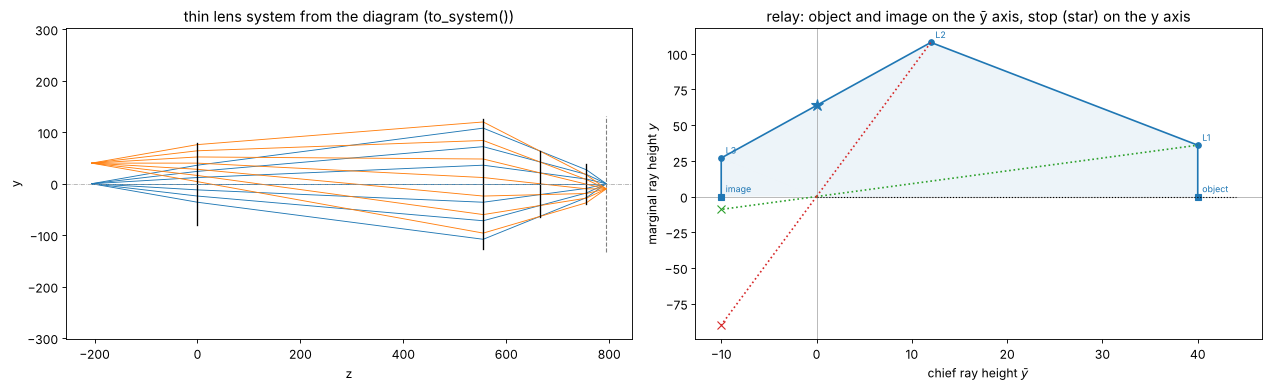

In [3]:
h = 40.0
relay = DelanoDiagram([h, h, 0.3*h, -0.25*h, -0.25*h], [0, 20, 60, 15, 0], -0.175*h,
                      labels=["object", "L1", "L2", "L3", "image"]).with_length(1000.0)
relay_system = relay.to_system(248.3e-6)
pr = relay_system.paraxial()
print("focal lengths", np.round(relay.focal_length, 1), "mm; spaces", np.round(relay.thickness, 1), "mm")
print(f"thin lens system: magnification {pr.magnification:.4f}, NA {pr.na:.4f}, "
      f"length {relay_system.object_distance + relay_system.image_z:.1f} mm, "
      f"entrance/exit pupil at {pr.ep_z:.1e}/{pr.xp_z:.1e} mm (telecentric)")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
relay_system.draw(axes[0], fields=[0.0, h])
axes[0].set_title("thin lens system from the diagram (to_system())")
relay.plot(axes[1], areas=True)
# conjugates lie on lines through the origin
axes[1].plot([0, 1.1*h], [0, 0], "k:", lw=1)
z_stop = relay.pupils().stop[0]
for k, c in [(1, "C2"), (2, "C3")]:
    z, m = relay.conjugate(3, k)
    q = m*relay.points[k]
    axes[1].plot([0, relay.ybar[k]], [0, relay.y[k]], ":", color=c)
    axes[1].plot([0, q[0]], [0, q[1]], ":", color=c)
    axes[1].plot(*q, "x", color=c, ms=8)
    print(f"image of {relay.labels[k]} in the last space: z = {z:.1f} mm, magnification {m:.3f}")
axes[1].set_title("relay: object and image on the ȳ axis, stop (star) on the y axis")
fig.tight_layout()

Object and image lie on the same line through the origin (the $\bar y$
axis): **conjugate points lie on lines through the origin**, with the ratio
of their distances from it as the magnification. The image of L1 in image
space (green cross) is $-1/4$ of L1, a virtual image 13 mm behind the wafer.
The relay is afocal (object and image space edges are parallel), so it has
no focal or principal points: `cardinal_points()` returns infinities.

## 3. Specification and sketch of the new lens

The specification fixes the ends of the polygon:

| | in the diagram |
|---|---|
| magnification −0.25 | object at $(h, 0)$, image at $(-h/4, 0)$ |
| telecentric object and image space | first and last edges vertical: $\bar y_1 = h$, $\bar y_{13} = -h/4$ |
| NA 0.7 (object side 0.175) | $H = -0.175\,h$; the slopes of the first and last edges follow |
| 1 m object to wafer | scale all $y$ (`with_length()`) |
| image field radius 13.6 mm (a 26 × 8 mm scanner slit) | $h = 54.4$ mm |
| flat field | Petzval sum $\sum\phi_k/n = 0$ |

Everything in between is design. Rules for drawing the polygon:

- It has to wind around the origin in one sense (here counterclockwise):
  a step back in angle would be a negative distance.
- Distances are areas: a lens close to the origin gets little room.
- The last space is the working distance (more precisely, from the rear
  principal plane of the last lens to the wafer): $t = y_{13}/\mathrm{NA}$.
- Lenses carry diameters $2(|y| + |\bar y|)$; with 1 m length and NA 0.7 the
  largest are about 250 mm.

The sketch below has the structure of the lens of section 1 with fewer
elements: two positive field lenses (L1, L2, telecentric object space), a
first waist (L3, L4 negative), a bulge (L5–L7), a second waist (L8, L9), and
the last bulge with the stop (L10–L13), which does most of the focusing to
NA 0.7. It is written in units of $h$ for $\bar y$ and of an arbitrary scale
for $y$ (`with_length()` fixes it).

In [4]:
WL = 248.3e-6                     # KrF, mm
N_SIO2 = rt.fused_silica(248.3)
M, LENGTH, NA = -0.25, 1000.0, 0.7
R_FIELD = 13.6                    # image field radius
h = R_FIELD/abs(M)                # object height
H = -NA*abs(M)*h                  # Lagrange invariant

# (ybar/h, y) of object, L1...L13, image
SKETCH = np.array([(1, 0), (1, 0.10), (0.94, 0.20), (0.80, 0.19), (0.68, 0.20), (0.62, 0.36),
                   (0.50, 0.54), (0.34, 0.60), (0.22, 0.46), (0.13, 0.43), (0.05, 0.70),
                   (-0.08, 0.88), (-0.20, 0.62), (-0.25, 0.08), (-0.25, 0)])
labels = ["object"] + [f"L{k}" for k in range(1, 14)] + ["image"]
sketch = DelanoDiagram(h*SKETCH[:, 0], SKETCH[:, 1], H, labels=labels).with_length(LENGTH)


def summary(d, name):
    print(f"{name}: Petzval sum {d.petzval_sum(N_SIO2)*1e3:+.3f}/m, NA {d.NA[0]:.3f} -> {d.NA[1]:.3f}, "
          f"magnification {d.magnification:.3f}, length {d.length:.1f} mm, stop at "
          f"{d.pupils().stop[0]:.0f} mm")
    print("  f    [mm]", " ".join(f"{f:7.0f}" for f in d.focal_length))
    print("  space[mm]", " ".join(f"{t:7.1f}" for t in d.thickness))
    print("  y*phi[%] ", " ".join(f"{v:7.1f}" for v in 100*d.y[1:-1]*d.power))
    print("  semi diam", " ".join(f"{v:7.1f}" for v in d.heights()[1:-1]))


summary(sketch, "sketch")

sketch: Petzval sum +0.472/m, NA 0.175 -> 0.700, magnification -0.250, length 1000.0 mm, stop at 701 mm
  f    [mm]    1521     116    -190    -172    1917     718      83     -81     -78     289     196     292     598
  space[mm]    86.1    91.3    16.0    26.5   104.0   133.3   100.2    21.0    30.0    59.8    86.1   108.8   119.7    17.2
  y*phi[%]      1.0    25.9   -15.1   -17.5     2.8    11.3   109.4   -85.3   -83.1    36.5    67.5    32.0     2.0
  semi diam    69.5    81.3    72.1    67.1    88.0   108.6   108.9    81.3    71.9   108.2   136.9   104.3    25.7


The sketch already has the intended signs and a small Petzval sum (a
Petzval radius of about 2 m). Its weak points are in the row "y*phi", the
bend $y_k\phi_k$ of the marginal ray at each lens (the whole lens bends it
by 0.875, from +0.175 to −0.7): L7, L8 and L9 at the sharp corner into the
second waist bend it by about ±1 each and cancel, which costs aberrations,
while L1, L5 and L13 do almost nothing; and the spaces around L3 and L8
are too short for real lenses.

`refine()` moves the points of the sketch (keeping the telecentric ends) to
a Petzval sum of zero, spaces of at least 35 mm, a working space of 45 mm,
semi diameters up to 125 mm and the signs of the sketch, while staying close
to it and spreading the bending of the marginal ray over the lenses. It is a
small least squares problem in the 24 coordinates of the inner points
(seconds).

refined: Petzval sum -0.000/m, NA 0.175 -> 0.700, magnification -0.250, length 1000.0 mm, stop at 693 mm
  f    [mm]    1063     177   -1376     -55     149     302     417    -194    -141     472     239     195    1673
  space[mm]   114.3    35.0    35.0    35.0    47.7   188.2    52.8    40.5    35.0    64.6    66.3   149.7    90.8    45.0
  y*phi[%]      1.9    14.4    -1.9   -48.7    34.6    27.9    18.8   -34.2   -48.5    21.8    51.6    48.0     1.9
  semi diam    74.4    78.1    66.3    56.2    91.0   113.3    99.7    79.7    76.7   106.3   125.3   106.2    45.1
thin lens system: m = -0.25000, NA = 0.7000, length = 1000.00 mm, telecentric: pupils at 1.4e+17 and 1.2e+19 mm


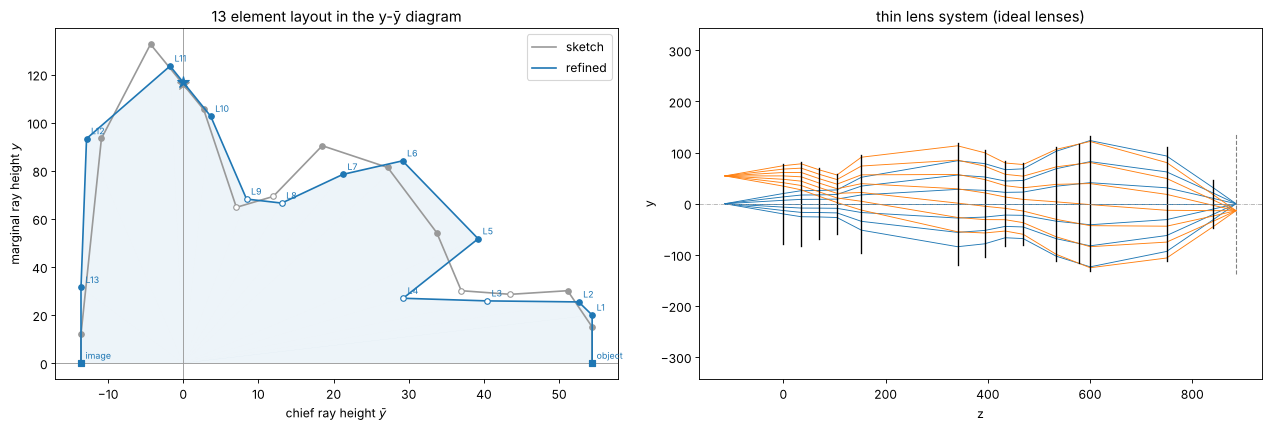

In [5]:
layout = refine(sketch, N_SIO2, min_space=35.0, spaces={-1: 45.0}, max_height=125.0, anchor=1.0)
summary(layout, "refined")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sketch.plot(axes[0], color="0.6", label="sketch", annotate=False)
layout.plot(axes[0], color="C0", label="refined", areas=True)
axes[0].legend()
axes[0].set_title("13 element layout in the y-ȳ diagram")
thin = layout.to_system(WL)
thin.draw(axes[1], fields=[0.0, h])
axes[1].set_title("thin lens system (ideal lenses)")
fig.tight_layout()
pt = thin.paraxial()
print(f"thin lens system: m = {pt.magnification:.5f}, NA = {pt.na:.4f}, "
      f"length = {thin.object_distance + thin.image_z:.2f} mm, telecentric: "
      f"pupils at {pt.ep_z:.1e} and {pt.xp_z:.1e} mm")

## 4. Thick lenses with the same first order properties

`thicken()` replaces every thin lens by a fused silica singlet of the same
power, with a centre thickness (here 0.4 × the paraxial semi diameter,
15–45 mm) and a shape factor $X = (c_1 + c_2)/(c_1 - c_2)$ (here
equiconvex/equiconcave, $X = 0$). The principal planes of each singlet sit
where the thin lens was, so the paraxial rays in all air spaces stay those
of the layout; only the distance between the principal planes of each lens
adds to the length, which `length=` takes out by rescaling the diagram. The
diagram of the thick system (one point per surface) goes through the same
lines as the thin one:

thick start system: m = -0.25000, NA = 0.7000, length = 1000.00 mm
Seidel sums at full field: W040 = -35663, W131 = 15614, W222 = 6946, W220 = 3371, W311 = 10781 waves


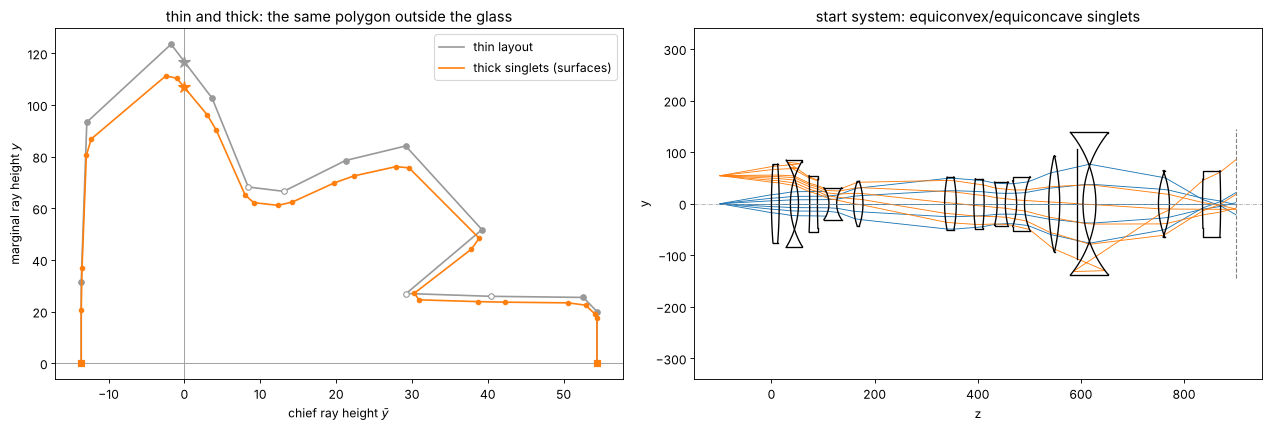

In [6]:
T = np.clip(0.2*layout.heights()[1:-1], 15, 45)
T[-1] = 35.0
start = thicken(layout, WL, rt.fused_silica, T, 0.0, length=LENGTH, check=False)
d_start = DelanoDiagram.from_system(start)
ps = start.paraxial()
print(f"thick start system: m = {ps.magnification:.5f}, NA = {ps.na:.4f}, "
      f"length = {start.object_distance + start.image_z:.2f} mm")
sd = start.seidel()
print(f"Seidel sums at full field: W040 = {sd.W040:.0f}, W131 = {sd.W131:.0f}, W222 = {sd.W222:.0f}, "
      f"W220 = {sd.W220:.0f}, W311 = {sd.W311:.0f} waves")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
layout.with_length(LENGTH).plot(axes[0], color="0.6", label="thin layout", annotate=False)
d_start.plot(axes[0], color="C1", label="thick singlets (surfaces)", annotate=False, signs=False)
axes[0].legend()
axes[0].set_title("thin and thick: the same polygon outside the glass")
start.draw(axes[1], fields=[0.0, h])
axes[1].set_title("start system: equiconvex/equiconcave singlets")
fig.tight_layout()

First order is now right, third order not at all: the lenses are not bent
yet, the spherical aberration alone is thousands of waves.

## 5. Correcting the aberrations with real rays

`LensOptimizer` varies all curvatures, all thicknesses (glass and air) and
the object distance and minimizes, by damped least squares, the residuals
of

- the transverse ray errors relative to the chief ray on four rings of the
  pupil at four fields (tolerance 0.1 µm),
- distortion against $m = -0.25$ (10 nm), image and object side
  telecentricity (2 mrad), the paraxial magnification,
- clearances: centre and edge thicknesses of at least 3 mm, air spaces of
  1 mm, 30 mm in front of the reticle, 8 mm working distance, checked at the
  rim of the full beam.

The length stays 1 m (the image distance is solved) and the object side
NA 0.175 (the stop size is solved). A local optimizer cannot open a lens
from scratch to NA 0.7 and the full field, the rays at the rim of the pupil
fail (they miss surfaces or are totally reflected). As in end-to-end lens
design by gradient descent, the aperture and the field are opened in
stages: the lens is corrected at 30 % of the NA and of the field first,
then at 40 %, ..., 100 %.

The full run takes about 15 minutes; it is reproduced in the cell below
with `RUN_FULL = True`. Otherwise only the first stage runs here and the
result of the full run is loaded from `raytrace.delano_krf_lens()`, which
stores it.

In [7]:
RUN_FULL = False

operands = [lo.ray_errors(tolerance=1e-4), lo.distortion(M), lo.image_telecentricity(tolerance=2e-3),
            lo.object_telecentricity(tolerance=2e-3), lo.paraxial_target("magnification", M, 1e-5),
            lo.clearances(min_image_distance=8.0, min_object_distance=30.0)]
start.ray_aiming = False  # paraxial pupil aiming is much faster and good enough here
opt = lo.LensOptimizer(start, operands, thicknesses=list(range(len(start.surfaces) - 1)),
                       object_distance=True, length=LENGTH, object_na=NA*abs(M))
stages = [(a, a) for a in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0)]
t0 = time.time()
if RUN_FULL:
    result = opt.run(stages=stages, max_nfev=200)
    design = result.system
else:
    result = opt.run(stages=stages[:1], max_nfev=60)
    design = rt.delano_krf_lens()
print(f"{len(opt.x)} variables, {len(opt.residuals())} residuals, {time.time() - t0:.0f} s")
for na_f, field_f, cost, nfev in result.stages:
    print(f"  stage at {na_f:.0%} NA, {field_f:.0%} field: cost {cost:.4g} after {nfev} evaluations")

53 variables, 206 residuals, 25 s
  stage at 30% NA, 30% field: cost 1.314e+04 after 60 evaluations


## 6. The corrected lens

design: m = -0.25009, NA = 0.6998, length = 1000.000 mm, working distance 19.0 mm, object distance 30.0 mm, 523 mm of glass, largest semi diameter 136 mm
paraxial chief ray slopes at full field: object side -169.90 mrad, image side -11.28 mrad


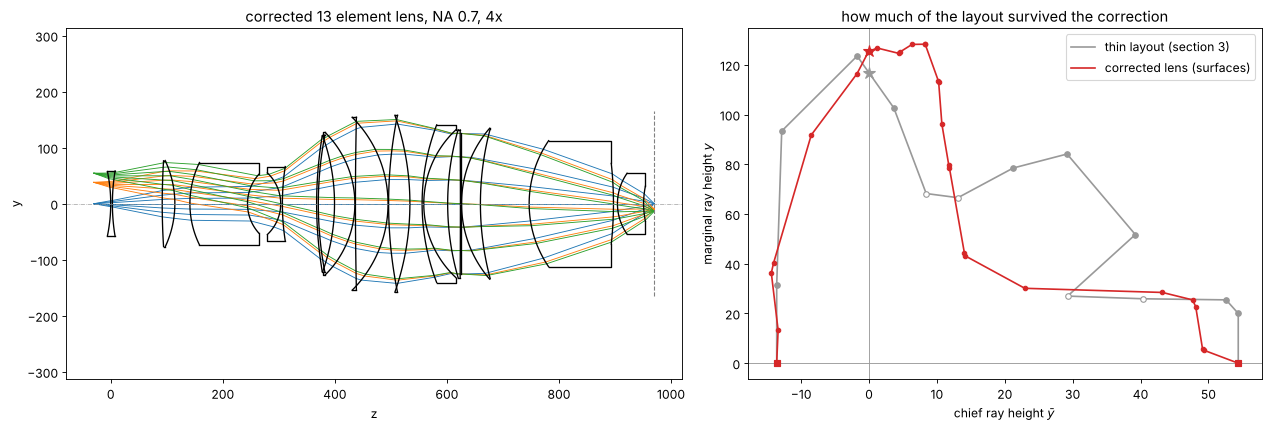

In [8]:
design.ray_aiming = True
pd = design.paraxial()
d_design = DelanoDiagram.from_system(design)
glass = [i for i in range(len(design.surfaces)) if not design._is_gap(design.n[i + 1])]
print(f"design: m = {pd.magnification:.5f}, NA = {pd.na:.4f}, "
      f"length = {design.object_distance + design.image_z:.3f} mm, working distance "
      f"{design.surfaces[-1].thickness:.1f} mm, object distance {design.object_distance:.1f} mm, "
      f"{sum(design.surfaces[i].thickness for i in glass):.0f} mm of glass, "
      f"largest semi diameter {np.max(d_design.heights()):.0f} mm")
print(f"paraxial chief ray slopes at full field: object side {1e3*d_design.slopes[0, 0]:.2f} mrad, "
      f"image side {1e3*d_design.slopes[-1, 0]:.2f} mrad")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
design.draw(axes[0], fields=[0.0, 0.7*h, h])
axes[0].set_title("corrected 13 element lens, NA 0.7, 4x")
layout.plot(axes[1], color="0.6", label="thin layout (section 3)", annotate=False)
d_design.plot(axes[1], color="C3", label="corrected lens (surfaces)", annotate=False, signs=False)
axes[1].legend()
axes[1].set_title("how much of the layout survived the correction")
fig.tight_layout()

r =  0.00 mm: RMS wavefront 1.345 waves, spot 1.95 µm rms
r =  2.72 mm: RMS wavefront 1.062 waves, spot 1.66 µm rms
r =  5.44 mm: RMS wavefront 0.466 waves, spot 1.14 µm rms
r =  8.16 mm: RMS wavefront 0.883 waves, spot 1.53 µm rms
r = 10.88 mm: RMS wavefront 1.266 waves, spot 2.53 µm rms
r = 13.60 mm: RMS wavefront 1.288 waves, spot 4.54 µm rms


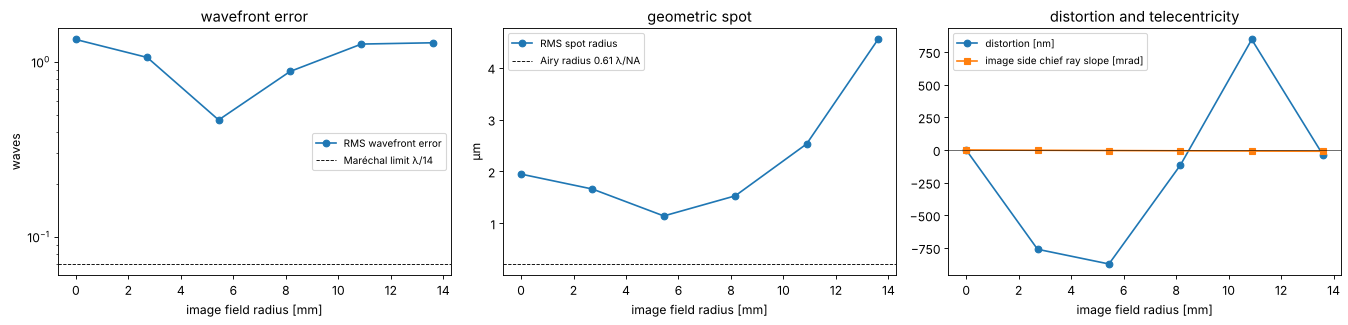

In [9]:
fields = np.linspace(0, 1, 6)
rms = np.array([design.rms_opd(field=f*h, N=48) for f in fields])
strehl = np.exp(-(2*np.pi*rms)**2)
spots = [design.spot_diagram(f*h, N=21) for f in fields]
dist, tele = [], []
for f in fields:
    c = design.trace_pupil(f*h, 0.0, 0.0)
    I, D = design._image_hits(c)
    dist.append((I[0, 1] - M*f*h)*1e6)
    tele.append(D[0, 1]/D[0, 2]*1e3)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
r_img = fields*R_FIELD
axes[0].plot(r_img, rms, "o-", label="RMS wavefront error")
axes[0].axhline(0.07, color="k", ls="--", lw=0.8, label="Maréchal limit λ/14")
axes[0].set_yscale("log"); axes[0].set_xlabel("image field radius [mm]"); axes[0].set_ylabel("waves")
axes[0].legend(fontsize=9); axes[0].set_title("wavefront error")
axes[1].plot(r_img, [s.rms*1e3 for s in spots], "o-", label="RMS spot radius")
axes[1].axhline(0.61*WL*1e3/NA, color="k", ls="--", lw=0.8, label="Airy radius 0.61 λ/NA")
axes[1].set_xlabel("image field radius [mm]"); axes[1].set_ylabel("µm"); axes[1].legend(fontsize=9)
axes[1].set_title("geometric spot")
axes[2].plot(r_img, dist, "o-", label="distortion [nm]")
axes[2].plot(r_img, tele, "s-", label="image side chief ray slope [mrad]")
axes[2].axhline(0, color="k", lw=0.5); axes[2].set_xlabel("image field radius [mm]")
axes[2].legend(fontsize=9); axes[2].set_title("distortion and telecentricity")
fig.tight_layout()
for f, w, s in zip(fields, rms, spots):
    print(f"r = {f*R_FIELD:5.2f} mm: RMS wavefront {w:.3f} waves, spot {s.rms*1e3:.2f} µm rms")

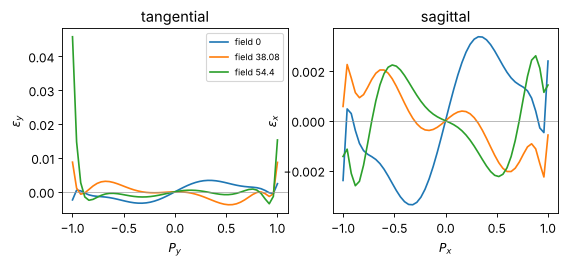

In [10]:
axes = design.plot_ray_fan(fields=[0.0, 0.7*h, h])

## 7. What the diagram did and what it did not

- **First order is exact.** The layout of section 3 fixes magnification,
  NA, length, telecentricity and the flat Petzval field before a single
  surface is bent; thickening keeps all of it, and the optimizer only
  has to hold it (the solves for length and NA, small residuals for
  telecentricity and magnification).
- **The correction moves the layout.** The diagram of the corrected lens
  (section 6) keeps the first waist (L3, L4) and the telecentric ends, but
  the optimizer smoothed the second waist into one large bulge around the
  stop and moved the strong positive power to L5–L7 and the last group.
  Real designs keep both waists because they need them for coma,
  astigmatism and distortion over a large field; with 13 lenses the
  optimizer found it cheaper to spend them on the aperture.
- **13 spherical lenses are not enough for NA 0.7 over 27 mm.** The design
  is corrected to about 0.5–1.3 waves RMS (1–4.5 µm spots), 7–20 times the
  Maréchal limit, with distortions of up to about 0.9 µm between the
  fields that the merit function samples. And it bought this with the
  **object side telecentricity**: the paraxial chief ray leaves the reticle
  at about 170 mrad at the edge of the field (image side 11 mrad), far from
  the specification. A polish with 10 times tighter telecentricity
  tolerances brings it to 10 mrad (image side 26 mrad), at 0.6–2.3 waves:
  with this few lenses, flat field, telecentricity and aperture compete.
  KrF lenses of this NA had about 30 elements and several aspheres;
  Caldwell's lens of section 1 needs 21 elements for NA 0.56. Some of the
  glass is also not manufacturable as it stands (centre thicknesses at the
  3 mm limit, a 150 mm thick element near the wafer). A run with r⁴ and r⁶
  aspheres on all surfaces was about 1.5–2 times better than the spherical
  one up to 90 % of the aperture, then lost rays at the rim in the last
  stage.

Exercises: give the optimizer aspheres (`aspheres=` of `LensOptimizer`, the
r⁴ and r⁶ terms of chosen surfaces), more lenses (draw them into the
sketch, e.g. a third lens in each waist), a smaller field or a lower NA, and
see how the residual wavefront error drops; add a ray error operand at
more fields and distortion at all of them; follow the diagram through the
stages of the optimization (`result.stages`, `DelanoDiagram.from_system()`).

In [11]:
print(f"run time {time.time() - t_start:.0f} s")

run time 42 s
